# Numerical certification and sampling

Energy conservation is necessary but insufficient. Check analytical solutions, propagation-step order, temporal sampling and window truncation independently.

All measurements here are synthetic. This notebook runs a small independent calculation and then inspects a retained study figure. It does not launch full training or overwrite the saved scientific results.

In [1]:

from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists() and (p / "src/optics_portfolio").exists())
%matplotlib inline

PROJECT = ROOT


## Calculate and inspect

Read the calculation before executing. Compare numerical values with the stated physical assumptions.

In [2]:
from optics_portfolio.validation import certify_fiber
certificate=certify_fiber()
print(json.dumps(certificate,indent=2))
assert certificate["passed"]

{
  "passed": true,
  "checks": [
    {
      "name": "fundamental_soliton_complex_field",
      "value": 5.11958107876348e-07,
      "limit": 2e-05,
      "passed": true
    },
    {
      "name": "gaussian_infinite_domain_solution",
      "value": 1.0628285238249512e-14,
      "limit": 1e-10,
      "passed": true
    },
    {
      "name": "strang_convergence_order",
      "value": 1.9998023277625918,
      "expected_interval": [
        1.8,
        2.2
      ],
      "passed": true
    }
  ],
  "sampling": {
    "edge_energy_fraction": 4.764215441228185e-15,
    "high_frequency_energy_fraction": 2.729130543830863e-23
  },
  "step_errors": [
    4.097578367835128e-05,
    1.0246188419332706e-05,
    2.561688368074065e-06
  ]
}


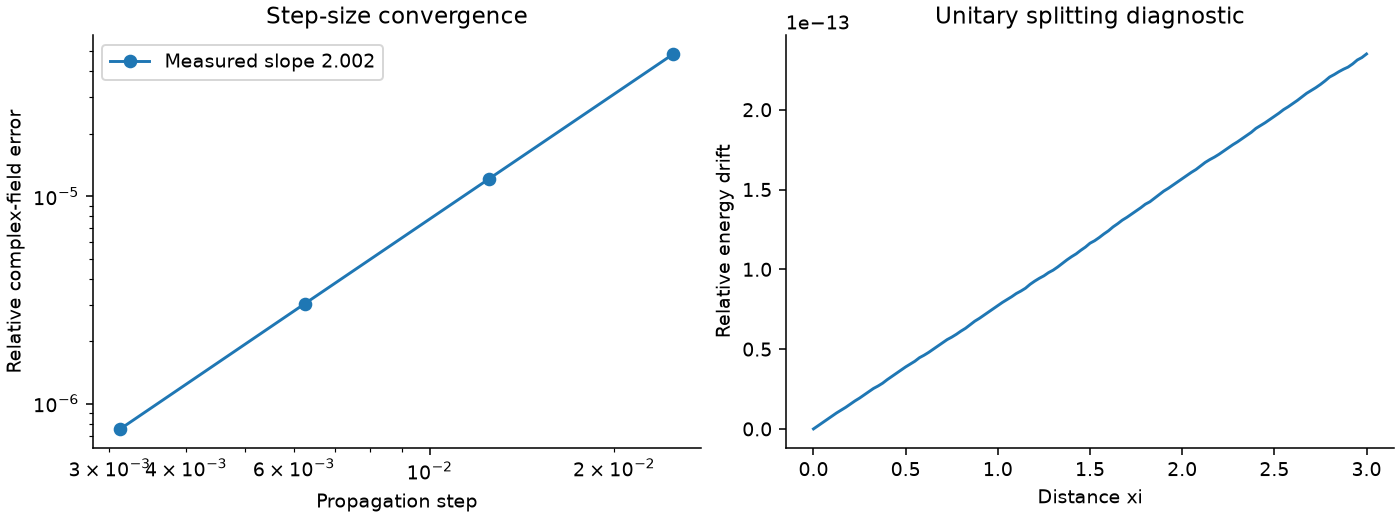

In [3]:
display(Image(filename=str(PROJECT / "results/validation.png")))

## Interpret and extend

Explain the finite-window error floor encountered in the initial build. Change window size at fixed pitch, then pitch at fixed window; describe why these are different experiments.

See `../report/technical_report.md` and the project README for the full experiment and limitations. Record your own changed settings and conclusions in a separate run.